# Exoplanet Taxonomic Clustering
**Goal:** Unsupervised clustering of exoplanets into physical classes (terrestrial, sub-Neptune, gas giant) using radius, mass, period, semi-major axis, eccentricity, and temperature.


**Pipeline:** Audit $\rightarrow$ EDA $\rightarrow$ Log Preprocessing $\rightarrow$ K-Means & Hierarchical Clustering $\rightarrow$ Evaluation.


## 1. Setup & Environment
Initializes random seeds (`seed=42`) and colorblind-safe styling for reproducible clustering and accessible visualizations.


In [2]:
# Core system and data libraries
import sys
import os
import warnings
import time

# Numerical and tabular processing
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Hierarchical clustering and dendrogram generation
from scipy.cluster.hierarchy import linkage, dendrogram

# Preprocessing, clustering algorithms, and evaluation metrics
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Global environment settings
warnings.filterwarnings('ignore')
np.random.seed(42)

# Visualization aesthetics: Colorblind-friendly palette and publication styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_palette('colorblind')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 120

print("Environment Initialized Successfully:")
print(f" - Python Version     : {sys.version.split()[0]}")
print(f" - NumPy Version      : {np.__version__}")
print(f" - Pandas Version     : {pd.__version__}")
import sklearn
print(f" - Scikit-Learn Version: {sklearn.__version__}")


Environment Initialized Successfully:
 - Python Version     : 3.12.0
 - NumPy Version      : 2.5.0
 - Pandas Version     : 3.0.5
 - Scikit-Learn Version: 1.9.0


## 2. Data Ingestion & Audit
Loaded 6,445 confirmed exoplanets across 6 physical features, dropping non-physical discovery metadata and missing stellar columns.
Eccentricity has the highest missing rate (16.5%), while radius and mass are under 1% missing.

In [3]:
# Define file path
dataset_path = 'D:\Desktop\exoplanets.csv'

# Complete candidate feature schema requested
target_requested_columns = [
    'pl_name',     # Planet Name (identifier)
    'pl_rade',     # Planet Radius [Earth radii]
    'pl_bmasse',   # Planet Mass [Earth masses]
    'pl_orbper',   # Orbital Period [days]
    'pl_orbsmax',  # Orbital Semimajor Axis [AU]
    'pl_orbeccen', # Orbital Eccentricity
    'pl_eqt',      # Equilibrium Temperature [K]
    'st_teff',     # Host Star Effective Temperature [K]
    'st_mass',     # Host Star Mass [Solar masses]
    'st_rad'       # Host Star Radius [Solar radii]
]

# Load raw dataset
raw_df = pd.read_csv(dataset_path)
print(f"Raw Dataset Ingested: {raw_df.shape[0]} rows, {raw_df.shape[1]} columns.")
print(f"Raw Columns: {list(raw_df.columns)}")

# Audit schema against available columns
available_target_cols = [c for c in target_requested_columns if c in raw_df.columns]
missing_target_cols = [c for c in target_requested_columns if c not in raw_df.columns]
extraneous_cols = [c for c in raw_df.columns if c not in target_requested_columns]

print(f"\nAvailable Target Columns ({len(available_target_cols)}): {available_target_cols}")
print(f"Requested but Absent Columns ({len(missing_target_cols)}): {missing_target_cols}")
print(f"Extraneous Metadata Columns Dropped ({len(extraneous_cols)}): {extraneous_cols}")

# Filter dataset to available target columns
df_filtered = raw_df[available_target_cols].copy()

# Set identifier 'pl_name' as dataframe index to isolate it from feature matrices
if 'pl_name' in df_filtered.columns:
    df_filtered.set_index('pl_name', inplace=True)

# Separate numerical feature matrix
feature_names = list(df_filtered.columns)
print(f"\nActive Feature Matrix Columns ({len(feature_names)}): {feature_names}")

# Structural Audit: Info and Head
print("\n--- Feature Data Types & Non-Null Counts ---")
df_filtered.info()

print("\n--- First 5 Exoplanet Records in Pipeline ---")
display(df_filtered.head())

# Missing value audit
missing_audit = pd.DataFrame({
    'Missing_Count': df_filtered.isnull().sum(),
    'Missing_Percentage': (df_filtered.isnull().sum() / len(df_filtered)) * 100
}).sort_values(by='Missing_Count', ascending=False)

print("\n--- Missing Value Profile ---")
display(missing_audit)


Raw Dataset Ingested: 6445 rows, 8 columns.
Raw Columns: ['pl_name', 'pl_bmasse', 'pl_rade', 'pl_orbper', 'pl_orbeccen', 'pl_orbsmax', 'pl_eqt', 'disc_year']

Available Target Columns (7): ['pl_name', 'pl_rade', 'pl_bmasse', 'pl_orbper', 'pl_orbsmax', 'pl_orbeccen', 'pl_eqt']
Requested but Absent Columns (3): ['st_teff', 'st_mass', 'st_rad']
Extraneous Metadata Columns Dropped (1): ['disc_year']

Active Feature Matrix Columns (6): ['pl_rade', 'pl_bmasse', 'pl_orbper', 'pl_orbsmax', 'pl_orbeccen', 'pl_eqt']

--- Feature Data Types & Non-Null Counts ---
<class 'pandas.DataFrame'>
Index: 6445 entries, HD 2039 b to TOI-789 c
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   pl_rade      6395 non-null   float64
 1   pl_bmasse    6414 non-null   float64
 2   pl_orbper    6092 non-null   float64
 3   pl_orbsmax   5953 non-null   float64
 4   pl_orbeccen  5379 non-null   float64
 5   pl_eqt       5909 non-null   float64
dty

,pl_rade,pl_bmasse,pl_orbper,pl_orbsmax,pl_orbeccen,pl_eqt
pl_name,,,,,,
HD 2039 b,12.700000,1999.1507,1120.000000,2.20000,0.71,210.84
HAT-P-8 b,15.692600,406.8224,3.076340,0.04496,0.00,1713.00
K2-43 b,4.510000,18.5000,3.471149,0.03784,0.07,939.30
Kepler-1753 b,2.226781,5.5900,16.004601,0.11790,0.00,583.00
Kepler-1176 b,2.450000,6.5700,24.173858,0.15890,0.00,595.00



--- Missing Value Profile ---


,Missing_Count,Missing_Percentage
pl_orbeccen,1066,16.539953
pl_eqt,536,8.316524
pl_orbsmax,492,7.633825
pl_orbper,353,5.477114
pl_rade,50,0.775795
pl_bmasse,31,0.480993


## 3. Exploratory Data Analysis
Distributions are heavily right-skewed due to detection biases, spanning several orders of magnitude in orbital period and distance.
Spearman rank correlations confirm expected orbital physics, including Kepler's Third Law ($r_s \approx 0.98$).

--- Descriptive Statistics and Distributional Moments ---


,count,mean,std,min,25%,median,75%,max,skewness,kurtosis
pl_rade,6395.0,5.846,5.411,0.310,1.850,2.860,11.900,8.720600e+01,1.721,12.023
pl_bmasse,6414.0,401.339,1133.324,0.020,4.320,9.320,188.076,9.534852e+03,4.399,22.068
pl_orbper,6092.0,70273.484,5152872.277,0.091,4.285,10.641,38.000,4.020000e+08,77.941,6080.342
pl_orbsmax,5953.0,15.422,345.542,0.004,0.052,0.103,0.313,1.900000e+04,39.797,1867.845
pl_orbeccen,5379.0,0.079,0.152,0.000,0.000,0.000,0.090,9.500000e-01,2.644,7.601
pl_eqt,5909.0,836.633,496.280,1.480,486.000,758.000,1095.000,7.777780e+03,1.626,11.039


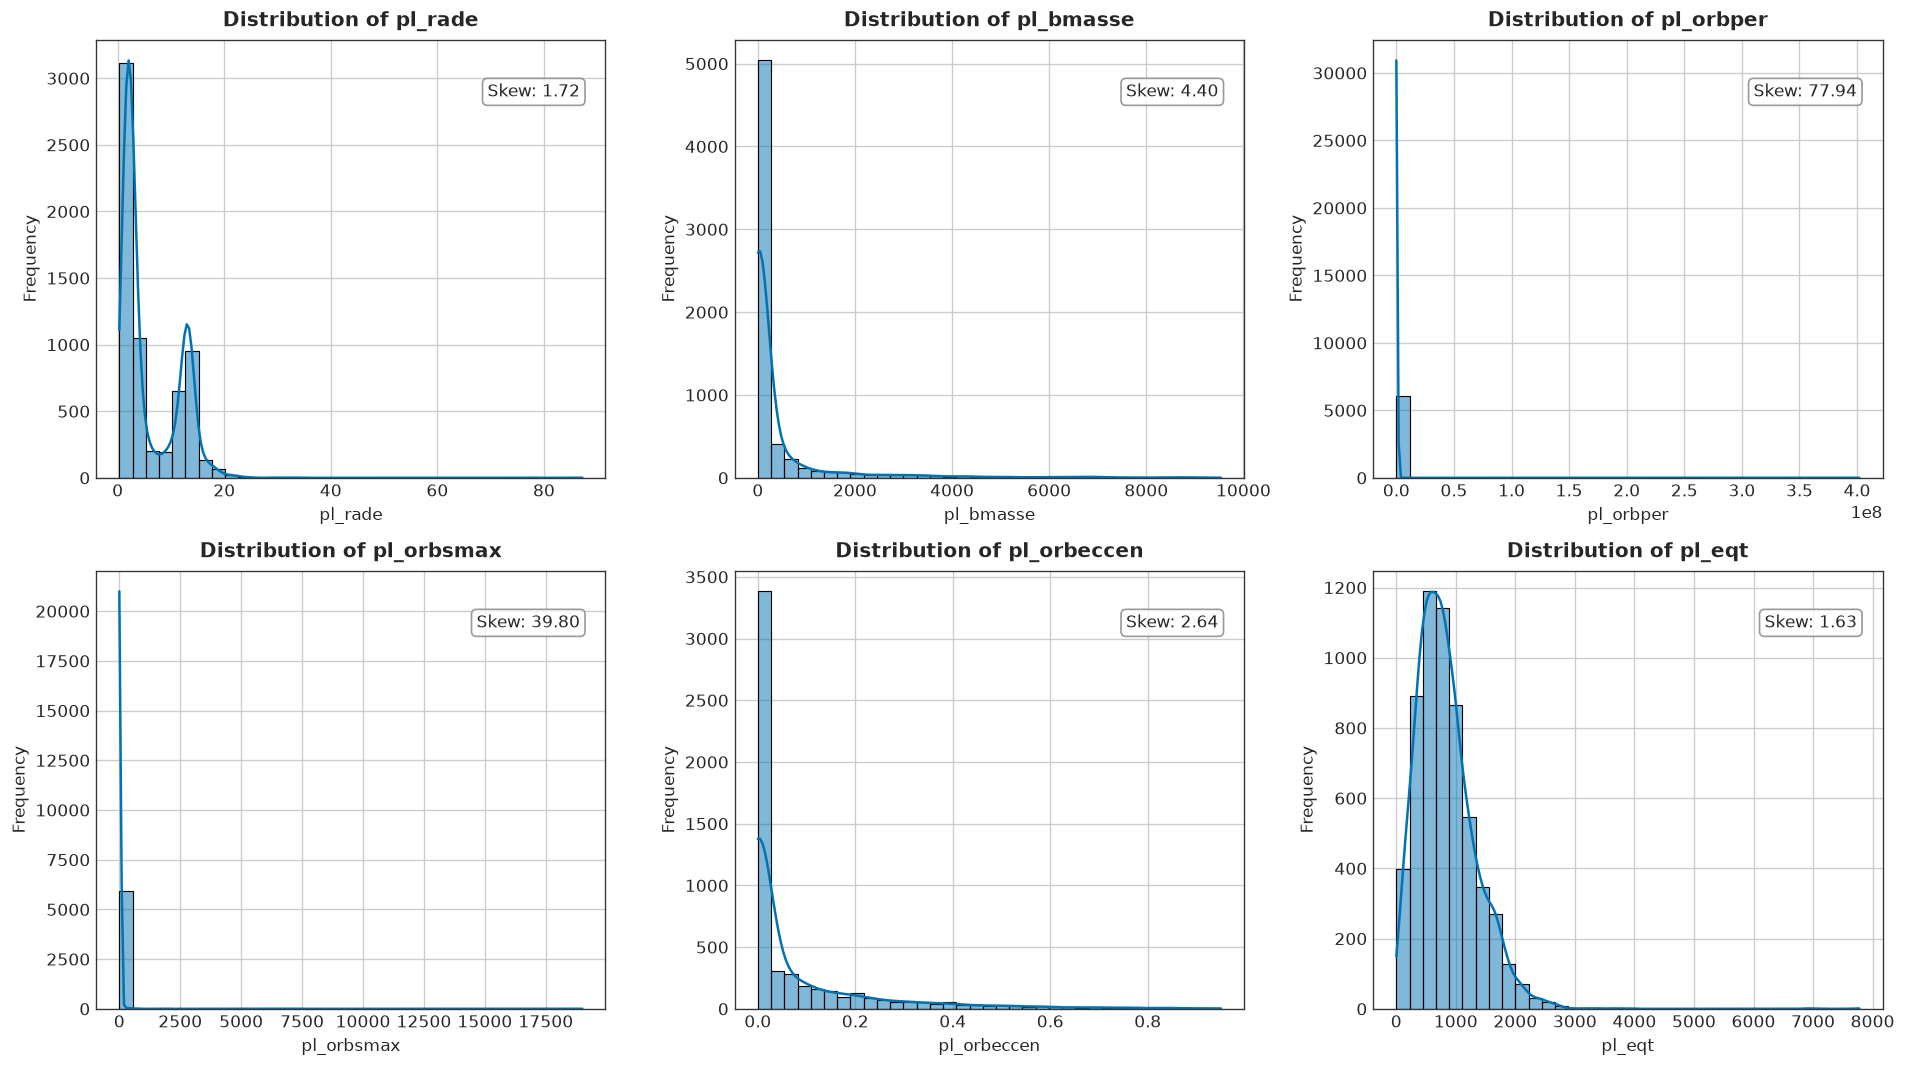

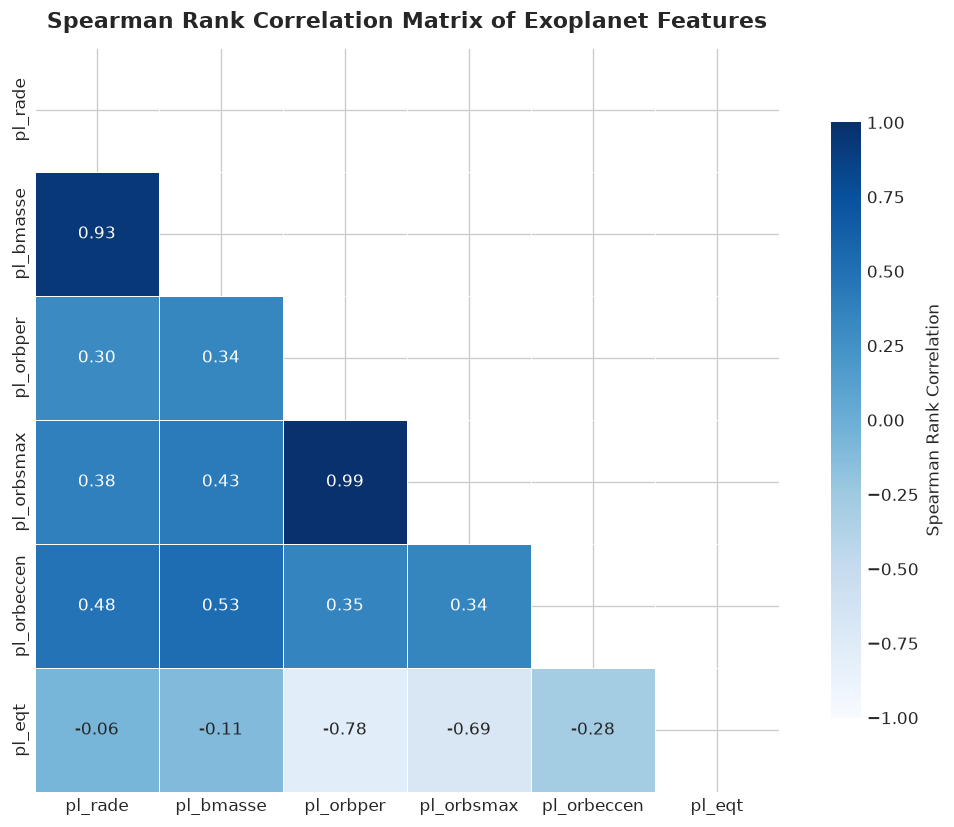

In [4]:
# Summary statistics table with distributional moments
stats_df = df_filtered.describe().T
stats_df['median'] = df_filtered.median()
stats_df['skewness'] = df_filtered.skew()
stats_df['kurtosis'] = df_filtered.kurtosis()
stats_df = stats_df[['count', 'mean', 'std', 'min', '25%', 'median', '75%', 'max', 'skewness', 'kurtosis']]

print("--- Descriptive Statistics and Distributional Moments ---")
display(stats_df.round(3))

# Distribution Plots (KDE and Histograms)
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(16, 9))
axes = axes.flatten()

palette = sns.color_palette('colorblind')
for i, col in enumerate(feature_names):
    ax = axes[i]
    sns.histplot(
        df_filtered[col].dropna(),
        kde=True,
        ax=ax,
        color=palette[0],
        bins=35
    )
    ax.set_title(f"Distribution of {col}", fontsize=12, fontweight='bold', pad=8)
    ax.set_xlabel(f"{col}", fontsize=10)
    ax.set_ylabel("Frequency", fontsize=10)
    
    # Annotate skewness
    skew_val = df_filtered[col].skew()
    ax.text(
        0.95, 0.90, f"Skew: {skew_val:.2f}",
        transform=ax.transAxes,
        ha='right', va='top',
        fontsize=10,
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='gray', alpha=0.8)
    )

plt.tight_layout()
plt.show()

# Correlation Matrix Heatmap
plt.figure(figsize=(9, 7))
corr_matrix = df_filtered.corr(method='spearman') # Spearman rank correlation captures monotonic non-linear relations
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=-1.0,
    vmax=1.0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8, "label": "Spearman Rank Correlation"}
)
plt.title("Spearman Rank Correlation Matrix of Exoplanet Features", fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()


## 4. Preprocessing & Feature Engineering
Applies median imputation for missing values, $\log_{10}$-transforms power-law physical features, and standardizes all dimensions to zero mean and unit variance.

In [5]:
# Separate features that span orders of magnitude vs bounded ratios
log_features = ['pl_rade', 'pl_bmasse', 'pl_orbper', 'pl_orbsmax', 'pl_eqt']
linear_features = ['pl_orbeccen']

# 1. Median Imputation (done in original units so medians preserve physical meaning)
imputer = SimpleImputer(strategy='median')
df_imputed = pd.DataFrame(
    imputer.fit_transform(df_filtered),
    columns=feature_names,
    index=df_filtered.index
)

# 2. Log10 transformation for power-law astrophysical properties
X_transformed = df_imputed.copy()
for col in log_features:
    X_transformed[col] = np.log10(X_transformed[col])

# 3. Standardization (now mean ≈ 0, std ≈ 1 across genuinely Gaussian-like scales)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_transformed)

df_scaled = pd.DataFrame(X_scaled, columns=feature_names, index=df_filtered.index)

print("Transformed & Scaled Data Inspection:")
display(df_scaled.describe().round(3).T[['mean', 'std', 'min', '50%', 'max']])


Transformed & Scaled Data Inspection:


,mean,std,min,50%,max
pl_rade,-0.0,1.0,-2.709,-0.310,3.378
pl_bmasse,-0.0,1.0,-2.943,-0.394,2.482
pl_orbper,0.0,1.0,-2.561,-0.233,8.292
pl_orbsmax,-0.0,1.0,-2.148,-0.266,6.982
pl_orbeccen,0.0,1.0,-0.464,-0.464,6.219
pl_eqt,0.0,1.0,-8.956,0.138,3.532


## 5. 
## Model 1: K-Means Clustering & Optimization
Partitions planets into $k$ clusters by minimizing inertia[cite: 1]. Optimal cluster count is evaluated across $k \in [2, 10]$ using the Elbow Method and Silhouette scores.


Running K-Means Hyperparameter Search (k=2 to 10)...
 - k= 2: Inertia=  23624.11 | Silhouette=0.4853 | DB=1.0207 | CH= 4103.47
 - k= 3: Inertia=  17511.92 | Silhouette=0.4150 | DB=1.0286 | CH= 3891.65
 - k= 4: Inertia=  15003.82 | Silhouette=0.2903 | DB=1.1039 | CH= 3386.58
 - k= 5: Inertia=  12969.60 | Silhouette=0.2968 | DB=1.2300 | CH= 3190.36
 - k= 6: Inertia=  11449.15 | Silhouette=0.3044 | DB=1.1553 | CH= 3061.80
 - k= 7: Inertia=  10532.11 | Silhouette=0.3112 | DB=1.1122 | CH= 2866.66
 - k= 8: Inertia=   9694.49 | Silhouette=0.3190 | DB=1.0919 | CH= 2748.48
 - k= 9: Inertia=   8881.10 | Silhouette=0.2870 | DB=1.1235 | CH= 2698.46
 - k=10: Inertia=   8425.12 | Silhouette=0.2613 | DB=1.1420 | CH= 2566.75


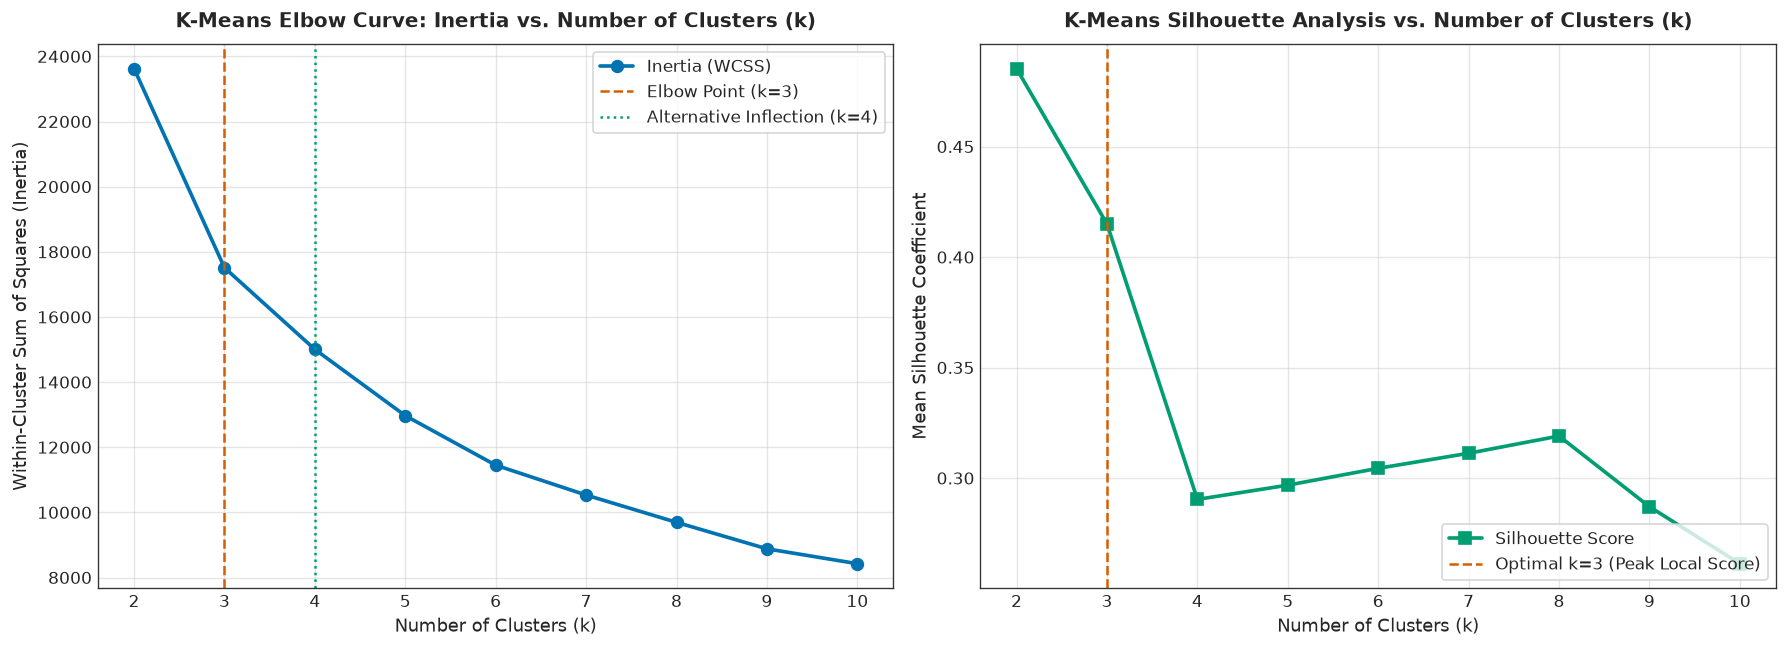


Cluster membership distribution for K-Means (k=3):
 - Cluster 0: 4149 exoplanets (64.4%)
 - Cluster 1: 923 exoplanets (14.3%)
 - Cluster 2: 1373 exoplanets (21.3%)


In [6]:
# Hyperparameter search across k in [2, 10]
k_range = range(2, 11)
inertias = []
silhouette_scores_k = []
davies_bouldin_scores_k = []
calinski_harabasz_scores_k = []

print("Running K-Means Hyperparameter Search (k=2 to 10)...")
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km_labels = km.fit_predict(X_scaled)
    
    inertias.append(km.inertia_)
    silhouette_scores_k.append(silhouette_score(X_scaled, km_labels))
    davies_bouldin_scores_k.append(davies_bouldin_score(X_scaled, km_labels))
    calinski_harabasz_scores_k.append(calinski_harabasz_score(X_scaled, km_labels))
    print(f" - k={k:2d}: Inertia={km.inertia_:10.2f} | Silhouette={silhouette_scores_k[-1]:.4f} | DB={davies_bouldin_scores_k[-1]:.4f} | CH={calinski_harabasz_scores_k[-1]:8.2f}")

# Plotting the Elbow Curve and Silhouette Profile
palette = sns.color_palette('colorblind')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

# Subplot 1: Inertia (Elbow Curve)
ax1.plot(k_range, inertias, marker='o', linewidth=2.2, markersize=7, color=palette[0], label='Inertia (WCSS)')
ax1.axvline(x=3, color=palette[3], linestyle='--', linewidth=1.5, label='Elbow Point (k=3)')
ax1.axvline(x=4, color=palette[2], linestyle=':', linewidth=1.5, label='Alternative Inflection (k=4)')
ax1.set_title("K-Means Elbow Curve: Inertia vs. Number of Clusters (k)", fontsize=12, fontweight='bold', pad=10)
ax1.set_xlabel("Number of Clusters (k)", fontsize=11)
ax1.set_ylabel("Within-Cluster Sum of Squares (Inertia)", fontsize=11)
ax1.set_xticks(k_range)
ax1.legend(loc='upper right', frameon=True)
ax1.grid(True, alpha=0.5)

# Subplot 2: Silhouette Score Profile
ax2.plot(k_range, silhouette_scores_k, marker='s', linewidth=2.2, markersize=7, color=palette[2], label='Silhouette Score')
ax2.axvline(x=3, color=palette[3], linestyle='--', linewidth=1.5, label='Optimal k=3 (Peak Local Score)')
ax2.set_title("K-Means Silhouette Analysis vs. Number of Clusters (k)", fontsize=12, fontweight='bold', pad=10)
ax2.set_xlabel("Number of Clusters (k)", fontsize=11)
ax2.set_ylabel("Mean Silhouette Coefficient", fontsize=11)
ax2.set_xticks(k_range)
ax2.legend(loc='lower right', frameon=True)
ax2.grid(True, alpha=0.5)

plt.tight_layout()
plt.show()

# Fit optimal models for comparison: k=3 (primary) and k=4 (alternative)
kmeans_k3 = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_scaled)
labels_km3 = kmeans_k3.labels_

kmeans_k4 = KMeans(n_clusters=4, random_state=42, n_init=10).fit(X_scaled)
labels_km4 = kmeans_k4.labels_

print("\nCluster membership distribution for K-Means (k=3):")
for c, count in enumerate(np.bincount(labels_km3)):
    print(f" - Cluster {c}: {count} exoplanets ({count/len(X_scaled)*100:.1f}%)")


## 6. 
## Model 2: Hierarchical Clustering
Constructs an agglomerative tree using Ward's linkage to reveal nested taxonomic hierarchies[cite: 1].
Dendrogram cuts validate the optimal cluster count identified during K-Means optimization.


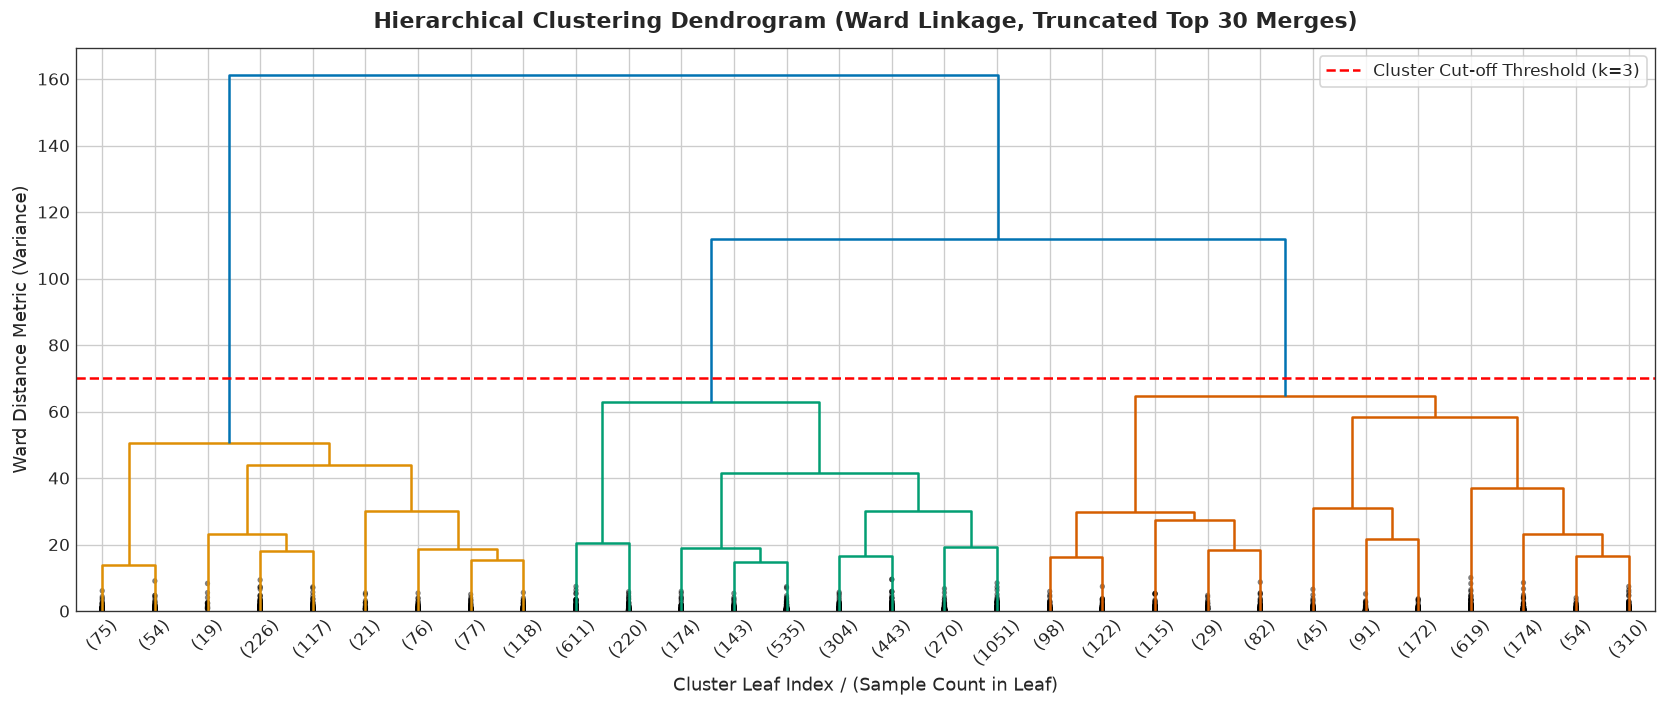

Agglomerative Linkage='ward': Cluster Counts = [1911, 783, 3751]
Agglomerative Linkage='complete': Cluster Counts = [915, 268, 5262]
Agglomerative Linkage='average': Cluster Counts = [6420, 3, 22]


In [7]:
# Compute Hierarchical Linkage Matrix using Ward's method
linkage_ward = linkage(X_scaled, method='ward')

# Generate publication-quality truncated Dendrogram
plt.figure(figsize=(14, 6))
dendro = dendrogram(
    linkage_ward,
    truncate_mode='lastp',
    p=30,                     # Show top 30 merged branches for clean interpretability
    leaf_rotation=45.,
    leaf_font_size=10.,
    show_contracted=True,
    color_threshold=70.0      # Cut-off distance visualizing cluster separation
)

# Annotate cut-off line
plt.axhline(y=70.0, color='red', linestyle='--', linewidth=1.5, label='Cluster Cut-off Threshold (k=3)')
plt.title("Hierarchical Clustering Dendrogram (Ward Linkage, Truncated Top 30 Merges)", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Cluster Leaf Index / (Sample Count in Leaf)", fontsize=11)
plt.ylabel("Ward Distance Metric (Variance)", fontsize=11)
plt.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.show()

# Fit Agglomerative models for Ward, Complete, and Average linkages at k=3
linkage_methods = ['ward', 'complete', 'average']
agg_models = {}
agg_labels = {}

for method in linkage_methods:
    model = AgglomerativeClustering(n_clusters=3, linkage=method)
    labels = model.fit_predict(X_scaled)
    agg_models[method] = model
    agg_labels[method] = labels
    counts = np.bincount(labels)
    print(f"Agglomerative Linkage='{method}': Cluster Counts = {counts.tolist()}")
